# Module 2 - Exploratory Data Analysis
**What this module covers:** descriptive statistics, the Severity distribution (class imbalance), **weather
influence** (with chi-square and Kruskal-Wallis tests), **accident hotspots** (top states/cities, KMeans,
DBSCAN and a grid-density hotspot table), **correlation analysis** (Pearson, Spearman, Cramer's V) and
time patterns (hour, weekday, month, year).

**Project tasks satisfied here:** *analyze weather influence*, *identify accident hotspots*, *correlation analysis*.

Input: `data/processed/accidents_clean.parquet` (399,581-row stratified sample from Module 1) and the full-file
hotspot grid from Module 1. Outputs: `reports/metrics/*` and `reports/figures/*`. Every insight below is printed by
code from the computed tables and collected in `reports/metrics/eda_insights.json`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from src import utils as U, viz as V, cleaning as C
from src.analysis import group_summary, infrastructure_summary, cramers_v, epsilon_squared

V.apply_style()
pd.set_option("display.max_columns", 40, "display.width", 200)
df = pd.read_parquet(U.CLEAN_PARQUET)
FIG, MET = U.FIGURES, U.METRICS
insights = {}
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| interpreter:", Path(sys.executable).parent.parent.name)
print(f"Rows: {len(df):,}  Columns: {df.shape[1]}")

Python 3.14.2 | pandas 3.1.0 | interpreter: .venv
Rows: 399,581  Columns: 45


## 1. Descriptive statistics

In [2]:
num = ["Severity", "Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
       "Wind_Speed(mph)", "Precipitation(in)", "Duration_min", "RoadFeatureCount"]
desc = df[num].describe().T
desc["skew"] = df[num].skew()
desc = desc.round(3)
desc.to_csv(MET / "eda_descriptive.csv")
desc

,count,mean,std,min,25%,50%,75%,max,skew
Severity,399581.0,2.212,0.488,1.00,2.000,2.000,2.000,4.000,1.814
Distance(mi),399581.0,0.527,1.256,0.00,0.000,0.030,0.467,9.669,4.335
Temperature(F),399581.0,61.658,18.794,6.00,49.000,64.000,76.000,99.000,-0.469
Humidity(%),399581.0,64.883,22.610,9.00,49.000,67.000,84.000,100.000,-0.398
Pressure(in),399581.0,29.543,0.970,24.16,29.380,29.860,30.030,30.510,-3.342
Visibility(mi),399581.0,9.059,2.310,0.25,10.000,10.000,10.000,10.000,-2.511
Wind_Speed(mph),399581.0,7.591,5.002,0.00,5.000,7.000,10.000,25.000,0.688
Precipitation(in),399581.0,0.004,0.024,0.00,0.000,0.000,0.000,0.230,7.304
Duration_min,397802.0,108.147,123.695,3.00,31.133,74.733,124.550,1440.000,3.493
RoadFeatureCount,399581.0,0.417,0.733,0.00,0.000,0.000,1.000,6.000,1.892


## 2. Severity distribution (class imbalance)

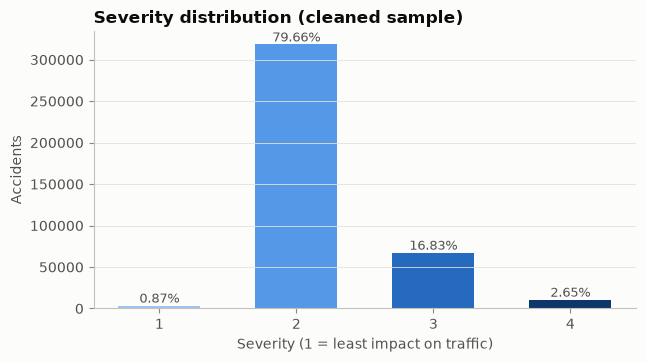

Severity 2 makes up 79.66% of accidents and Severity 1 only 0.87%; the largest class is 91x the smallest, so accuracy alone is misleading and macro-F1 is used in Module 4.


In [3]:
sev = df["Severity"].value_counts().sort_index()
sev_pct = (100 * sev / sev.sum()).round(2)
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(sev.index.astype(str), sev.values, color=[V.SEVERITY[s] for s in sev.index], width=0.6)
for b, p in zip(bars, sev_pct):
    ax.annotate(f"{p}%", (b.get_x() + b.get_width() / 2, b.get_height()), ha="center", va="bottom", fontsize=9, color=V.INK2)
ax.set(title="Severity distribution (cleaned sample)", xlabel="Severity (1 = least impact on traffic)", ylabel="Accidents")
V.save(fig, FIG / "severity_distribution.png")
imb = sev.max() / sev.min()
insights["severity"] = (f"Severity 2 makes up {sev_pct[2]}% of accidents and Severity 1 only {sev_pct[1]}%; "
                        f"the largest class is {imb:.0f}x the smallest, so accuracy alone is misleading and macro-F1 is used in Module 4.")
print(insights["severity"])

## 3. Weather influence
### 3.1 Count and severity by weather group

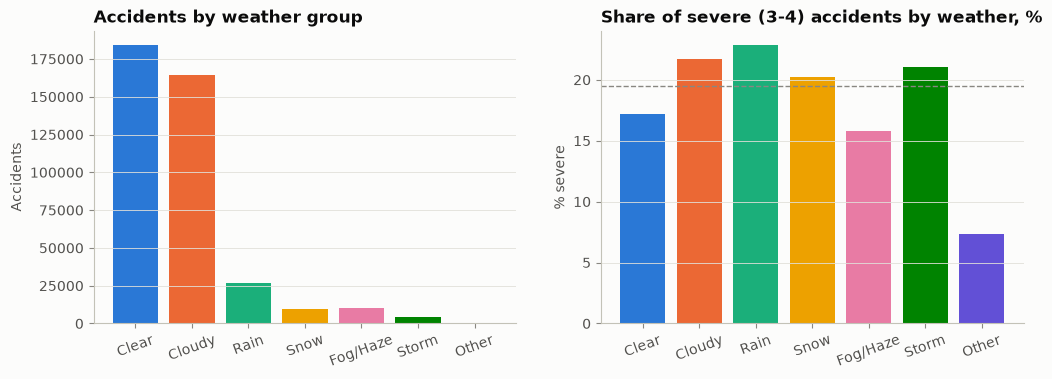

,WeatherGroup,accidents,avg_severity,severe_pct,share_of_accidents_pct
0,Clear,184327,2.1877,17.16,46.13
1,Cloudy,164458,2.2350,21.68,41.16
2,Rain,26457,2.2491,22.87,6.62
3,Fog/Haze,10321,2.1751,15.81,2.58
4,Snow,9264,2.2409,20.20,2.32
5,Storm,4590,2.2207,21.05,1.15
6,Other,164,2.0976,7.32,0.04


In [4]:
order = [g for g in U.WEATHER_GROUPS if g in df["WeatherGroup"].unique()]
by_weather = group_summary(df, "WeatherGroup")
by_weather["share_of_accidents_pct"] = (100 * by_weather["accidents"] / len(df)).round(2)
by_weather.to_csv(MET / "by_weather.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bw = by_weather.set_index("WeatherGroup").loc[order]
axes[0].bar(bw.index, bw["accidents"], color=[V.WEATHER_COLORS[g] for g in bw.index])
axes[0].set(title="Accidents by weather group", ylabel="Accidents")
axes[1].bar(bw.index, bw["severe_pct"], color=[V.WEATHER_COLORS[g] for g in bw.index])
axes[1].axhline(100 * (df["Severity"] >= 3).mean(), color=V.MUTED, ls="--", lw=1)
axes[1].set(title="Share of severe (3-4) accidents by weather, %", ylabel="% severe")
for a in axes: a.tick_params(axis="x", rotation=20)
V.save(fig, FIG / "weather_counts_severity.png")
by_weather

In [5]:
ct = pd.crosstab(df["WeatherGroup"], df["Severity"])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
v_weather = cramers_v(df["WeatherGroup"], df["Severity"])
top_w = bw.drop(index="Other", errors="ignore")["severe_pct"]
overall_severe = round(100 * (df["Severity"] >= 3).mean(), 2)
print(f"Chi-square WeatherGroup x Severity: chi2={chi2:,.1f}, dof={dof}, p={p_chi:.3g}, Cramer's V={v_weather:.3f}")
insights["weather"] = (f"{top_w.idxmax()} has the highest severe share ({top_w.max()}%) vs {top_w.idxmin()} the lowest "
                       f"({top_w.min()}%); overall {overall_severe}%. The link is significant (chi-square p{'<1e-300' if p_chi == 0 else f'={p_chi:.2g}'}) but weak "
                       f"(Cramer's V={v_weather:.3f}).")
print(insights["weather"])

Chi-square WeatherGroup x Severity: chi2=1,818.5, dof=18, p=0, Cramer's V=0.039
Rain has the highest severe share (22.87%) vs Fog/Haze the lowest (15.81%); overall 19.47%. The link is significant (chi-square p<1e-300) but weak (Cramer's V=0.039).


### 3.2 Numeric weather variables vs Severity (Kruskal-Wallis)
Kruskal-Wallis compares the distributions of a numeric variable across the four Severity levels without assuming
normality. With ~400k rows almost any difference is "significant", so the effect size epsilon-squared is reported
too (< 0.01 negligible, 0.01-0.06 small, 0.06-0.14 medium, > 0.14 large).

In [6]:
wcols = ["Temperature(F)", "Visibility(mi)", "Precipitation(in)", "Wind_Speed(mph)", "Humidity(%)", "Pressure(in)"]
rows = []
for c in wcols:
    groups = [g[c].values for _, g in df.groupby("Severity")]
    h, p = stats.kruskal(*groups)
    rows.append({"variable": c, "H": round(h, 1), "p_value": p, "epsilon_squared": round(epsilon_squared(h, len(df)), 4),
                 **{f"median_sev{s}": round(float(g[c].median()), 2) for s, g in df.groupby("Severity")}})
kw = pd.DataFrame(rows).sort_values("epsilon_squared", ascending=False)
kw.to_csv(MET / "weather_kruskal.csv", index=False)
U.save_json({"chi2_weathergroup_severity": {"chi2": chi2, "dof": dof, "p_value": p_chi, "cramers_v": v_weather},
             "kruskal": kw.to_dict(orient="records")}, MET / "weather_tests.json")
kw

,variable,H,p_value,epsilon_squared,median_sev1,median_sev2,median_sev3,median_sev4
5,Pressure(in),4234.3,0.000000e+00,0.0106,29.54,29.84,29.92,29.81
0,Temperature(F),1544.9,0.000000e+00,0.0039,73.00,63.00,64.90,60.10
3,Wind_Speed(mph),925.5,2.630466e-200,0.0023,7.00,7.00,7.00,7.00
2,Precipitation(in),274.4,3.377560e-59,0.0007,0.00,0.00,0.00,0.00
4,Humidity(%),194.6,6.100702e-42,0.0005,67.00,67.00,67.00,70.00
1,Visibility(mi),166.4,7.661250e-36,0.0004,10.00,10.00,10.00,10.00


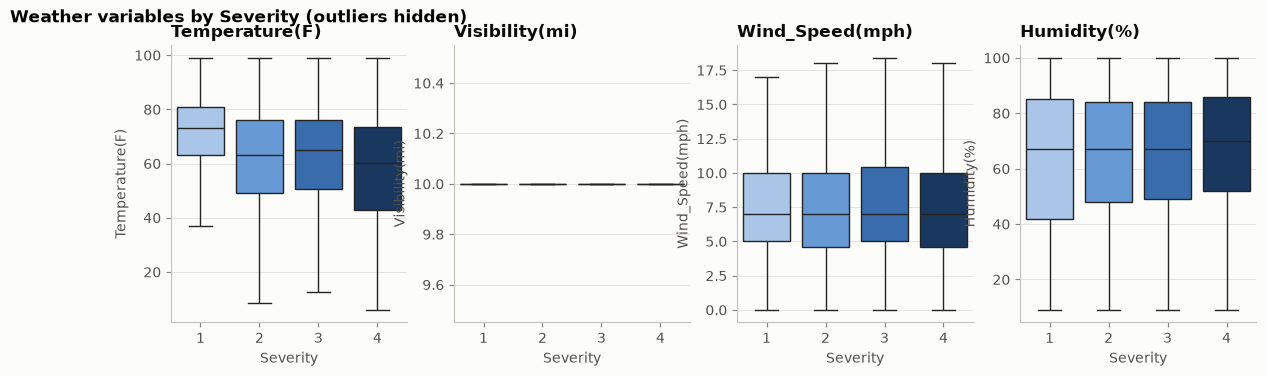

Strongest numeric weather effect: Pressure(in) (epsilon^2=0.0106); all six effects are below 0.06 (negligible/small), so single weather readings separate severity levels only slightly.


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for a, c in zip(axes, ["Temperature(F)", "Visibility(mi)", "Wind_Speed(mph)", "Humidity(%)"]):
    sns.boxplot(data=df, x="Severity", y=c, hue="Severity", palette=V.SEVERITY, legend=False, ax=a,
                showfliers=False, linewidth=1)
    a.set_title(c)
fig.suptitle("Weather variables by Severity (outliers hidden)", x=0.01, ha="left", fontweight="bold")
V.save(fig, FIG / "weather_numeric_by_severity.png")
k0 = kw.iloc[0]
insights["weather_numeric"] = (f"Strongest numeric weather effect: {k0['variable']} (epsilon^2={k0['epsilon_squared']}); " +
                               ("all six effects are below 0.06 (negligible/small), so single weather readings separate severity levels only slightly."
                                if kw["epsilon_squared"].max() < 0.06 else "at least one effect is medium or larger."))
print(insights["weather_numeric"])

## 4. Accident hotspots
### 4.1 Top states and cities (full 7.7M-row file, from the Module 1 chunked pass)

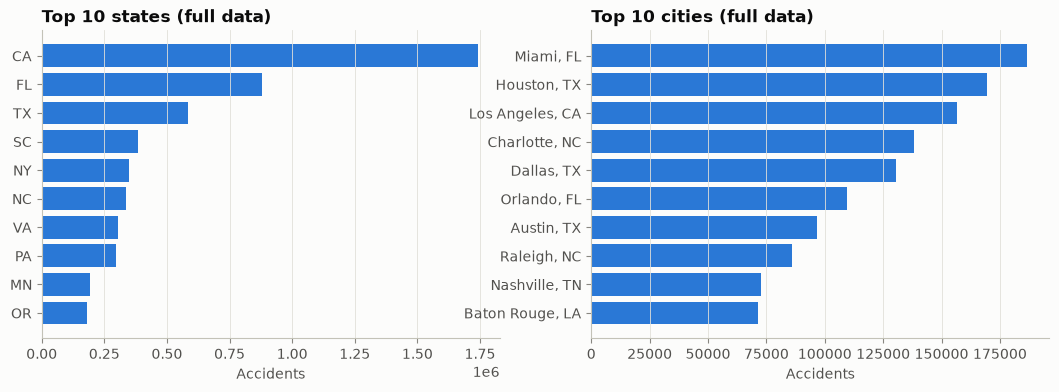

CA, FL and TX record the most accidents (41.5% of all); top city is Miami, FL (186,768). Counts are not rates (no traffic volume).


,State,accidents,severe_pct,City,State,accidents,severe_pct
0,CA,1741433,16.38,Miami,FL,186768,9.00
1,FL,880192,13.32,Houston,TX,169428,18.00
2,TX,582837,21.90,Los Angeles,CA,156491,22.92
3,SC,382557,11.91,Charlotte,NC,138345,5.59
4,NY,347960,23.22,Dallas,TX,130303,26.20
5,NC,338199,11.83,Orlando,FL,109690,6.45
6,VA,303301,22.92,Austin,TX,96604,9.23
7,PA,296620,15.81,Raleigh,NC,86066,9.89
8,MN,192084,16.01,Nashville,TN,72670,15.10
9,OR,179660,8.70,Baton Rouge,LA,71588,9.54


In [8]:
grid = pd.read_parquet(U.DATA_PROCESSED / "full_hotspot_grid.parquet")
state_full = (grid.groupby("State").agg(accidents=("n", "sum"), severe=("severe", "sum")).reset_index()
              .sort_values("accidents", ascending=False, ignore_index=True))
state_full["severe_pct"] = (100 * state_full["severe"] / state_full["accidents"]).round(2)
city_full = (grid.dropna(subset=["City"]).groupby(["City", "State"]).agg(accidents=("n", "sum"), severe=("severe", "sum"))
             .reset_index().sort_values("accidents", ascending=False, ignore_index=True))
city_full["severe_pct"] = (100 * city_full["severe"] / city_full["accidents"]).round(2)
state_full.drop(columns="severe").to_csv(MET / "top_states_full.csv", index=False)
city_full.head(25).drop(columns="severe").to_csv(MET / "top_cities_full.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
s10, c10 = state_full.head(10), city_full.head(10)
axes[0].barh(s10["State"][::-1], s10["accidents"][::-1], color=V.PRIMARY); axes[0].set(title="Top 10 states (full data)", xlabel="Accidents")
axes[1].barh((c10["City"] + ", " + c10["State"])[::-1], c10["accidents"][::-1], color=V.PRIMARY); axes[1].set(title="Top 10 cities (full data)", xlabel="Accidents")
for a in axes: a.grid(axis="x"); a.grid(axis="y", visible=False)
V.save(fig, FIG / "top_states_cities.png")
top3 = s10.head(3)
insights["states"] = (f"{top3.iloc[0]['State']}, {top3.iloc[1]['State']} and {top3.iloc[2]['State']} record the most accidents "
                      f"({100 * top3['accidents'].sum() / state_full['accidents'].sum():.1f}% of all); top city is "
                      f"{c10.iloc[0]['City']}, {c10.iloc[0]['State']} ({c10.iloc[0]['accidents']:,}). Counts are not rates (no traffic volume).")
print(insights["states"])
pd.concat([s10.drop(columns="severe").reset_index(drop=True), c10.drop(columns="severe").reset_index(drop=True)], axis=1)

### 4.2 Grid-density hotspots (full data) -> `reports/metrics/hotspots.csv`
Every accident in the full file was assigned to a 0.1 x 0.1 degree cell (about 11 km x 9 km). The ten densest cells
are the hotspot table; each is labelled with its most frequent City, State.

In [9]:
hot = C.hotspot_table(grid, top=10)
hot.to_csv(MET / "hotspots.csv", index=False)
insights["hotspots"] = (f"Densest 0.1-degree cell: around {hot.iloc[0]['label']} with {hot.iloc[0]['accidents']:,} accidents; "
                        f"the top 10 cells hold {100 * hot['accidents'].sum() / state_full['accidents'].sum():.1f}% of all accidents.")
print(insights["hotspots"])
hot

Densest 0.1-degree cell: around Los Angeles, CA with 50,254 accidents; the top 10 cells hold 4.6% of all accidents.


,rank,label,City,State,center_lat,center_lng,accidents,avg_severity,severe_pct
0,1,"Los Angeles, CA",Los Angeles,CA,34.05,-118.25,50254,2.239,23.2
1,2,"Miami, FL",Miami,FL,25.75,-80.35,42955,2.023,1.9
2,3,"Miami, FL",Miami,FL,25.85,-80.25,37466,2.206,19.1
3,4,"Los Angeles, CA",Los Angeles,CA,33.95,-118.25,36294,2.188,18.6
4,5,"Charlotte, NC",Charlotte,NC,35.25,-80.85,36259,2.076,9.1
5,6,"Baton Rouge, LA",Baton Rouge,LA,30.45,-91.15,33612,2.126,13.4
6,7,"Nashville, TN",Nashville,TN,36.15,-86.75,33140,2.193,19.9
7,8,"Orlando, FL",Orlando,FL,28.45,-81.45,30216,2.065,6.2
8,9,"Los Angeles, CA",Los Angeles,CA,34.05,-118.15,29171,2.213,20.8
9,10,"Bronx, NY",Bronx,NY,40.85,-73.95,27631,2.339,32.3


### 4.3 KMeans on coordinates (k chosen by elbow + silhouette on a subsample)
Longitude is scaled by cos(mean latitude) so one unit is roughly the same distance in both directions.
KMeans is fitted on a 50,000-row subsample; silhouette is computed on 10,000 of those rows.

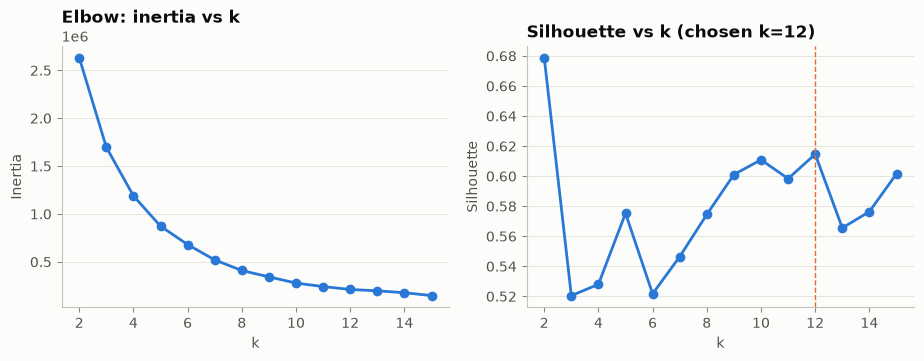

Best silhouette overall: k=2; chosen k=12 (best silhouette with k>=5, so that clusters stay regional rather than splitting the country in two or three)


In [10]:
sub = df.sample(50_000, random_state=U.RANDOM_STATE)
lat0 = np.deg2rad(sub["Start_Lat"].mean())
X = np.c_[sub["Start_Lat"], sub["Start_Lng"] * np.cos(lat0)]
rng = np.random.RandomState(U.RANDOM_STATE); sil_idx = rng.choice(len(X), 10_000, replace=False)
sel = []
for k in range(2, 16):
    km = KMeans(n_clusters=k, n_init=5, random_state=U.RANDOM_STATE).fit(X)
    sel.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X[sil_idx], km.labels_[sil_idx])})
sel = pd.DataFrame(sel); sel.to_csv(MET / "kmeans_selection.csv", index=False)
cand = sel[sel["k"] >= 5]
K = int(cand.loc[cand["silhouette"].idxmax(), "k"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(sel["k"], sel["inertia"], marker="o", color=V.PRIMARY); axes[0].set(title="Elbow: inertia vs k", xlabel="k", ylabel="Inertia")
axes[1].plot(sel["k"], sel["silhouette"], marker="o", color=V.PRIMARY); axes[1].axvline(K, color=V.ACCENT, ls="--", lw=1)
axes[1].set(title=f"Silhouette vs k (chosen k={K})", xlabel="k", ylabel="Silhouette")
V.save(fig, FIG / "kmeans_selection.png")
print(f"Best silhouette overall: k={int(sel.loc[sel.silhouette.idxmax(), 'k'])}; chosen k={K} (best silhouette with k>=5, "
      "so that clusters stay regional rather than splitting the country in two or three)")

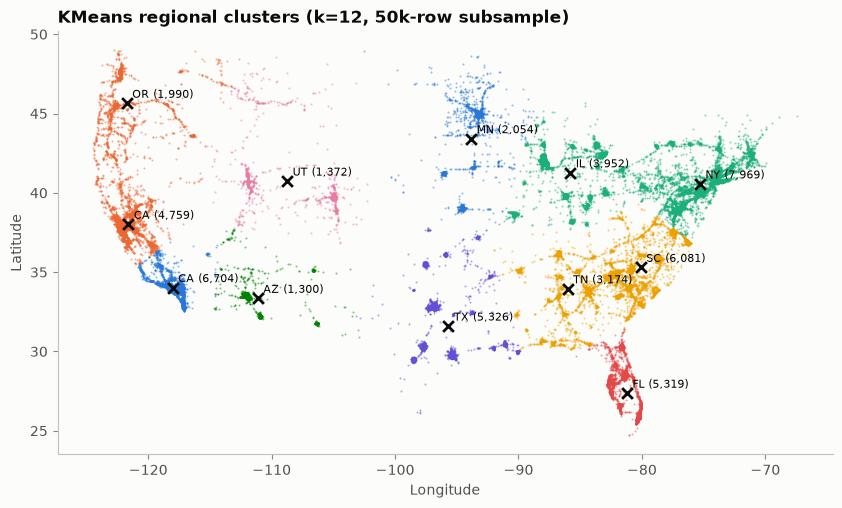

,kmeans,accidents,avg_severity,severe_pct,center_lat,center_lng,main_state
0,2,7969,2.2601,21.86,40.556706,-75.307526,NY
1,8,6704,2.1944,19.02,34.018914,-118.018271,CA
2,11,6081,2.1510,13.85,35.292713,-80.096716,SC
3,6,5326,2.1885,18.38,31.592872,-95.679588,TX
4,7,5319,2.1431,13.42,27.359645,-81.217483,FL
5,1,4759,2.1374,13.99,38.011749,-121.606387,CA
6,10,3952,2.3811,34.51,41.258375,-85.804938,IL
7,3,3174,2.3214,28.67,33.944785,-86.023077,TN
8,0,2054,2.2303,20.40,43.409759,-93.836768,MN
9,9,1990,2.1864,15.98,45.639533,-121.744703,OR


In [11]:
km = KMeans(n_clusters=K, n_init=10, random_state=U.RANDOM_STATE).fit(X)
sub = sub.assign(kmeans=km.labels_)
ksum = group_summary(sub, "kmeans").merge(
    sub.groupby("kmeans").agg(center_lat=("Start_Lat", "mean"), center_lng=("Start_Lng", "mean"),
                              main_state=("State", lambda s: s.mode().iloc[0])).reset_index(), on="kmeans")
ksum.round(3).to_csv(MET / "kmeans_clusters.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 5.5))
pal = (V.CATEGORICAL * 3)[:K]
for k in range(K):
    m = sub["kmeans"] == k
    ax.scatter(sub.loc[m, "Start_Lng"], sub.loc[m, "Start_Lat"], s=2, color=pal[k], alpha=0.5, linewidths=0)
ax.scatter(ksum["center_lng"], ksum["center_lat"], s=60, color=V.INK, marker="x")
for _, r in ksum.iterrows():
    ax.annotate(f"{r['main_state']} ({r['accidents']:,})", (r["center_lng"], r["center_lat"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(title=f"KMeans regional clusters (k={K}, 50k-row subsample)", xlabel="Longitude", ylabel="Latitude"); ax.grid(False)
V.save(fig, FIG / "kmeans_clusters_map.png")
ksum

### 4.4 DBSCAN (haversine) - dense urban clusters
DBSCAN finds clusters of arbitrary shape and labels sparse points as noise. Settings: eps = 2 km, min_samples = 25,
haversine distance on a 100,000-row subsample (a first try with 1.5 km / 40 points on 30,000 rows was too sparse and
labelled almost everything as noise).

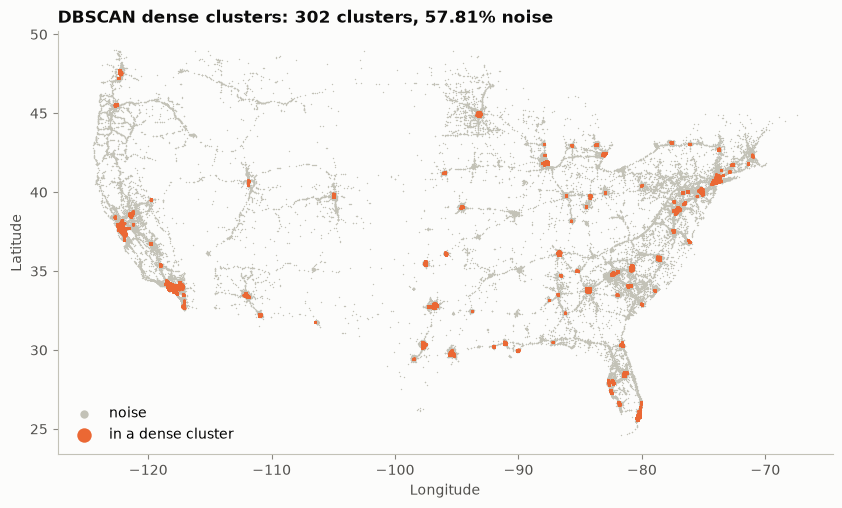

DBSCAN (2 km, 25 points) finds 302 dense urban clusters; the largest is around Los Angeles, CA; 57.81% of accidents are outside any dense cluster.


,points,avg_severity,city,state
0,5887,2.227,Los Angeles,CA
1,3418,2.121,Miami,FL
2,1437,2.308,Bronx,NY
3,1437,2.214,Houston,TX
4,1432,2.052,Charlotte,NC
5,1372,2.310,Dallas,TX
6,1012,2.098,Raleigh,NC
7,1011,2.079,Orlando,FL
8,956,2.124,Austin,TX
9,912,2.334,Oakland,CA


In [12]:
sub2 = df.sample(100_000, random_state=U.RANDOM_STATE)
coords = np.deg2rad(sub2[["Start_Lat", "Start_Lng"]].values)
db = DBSCAN(eps=2.0 / 6371.0, min_samples=25, metric="haversine", algorithm="ball_tree").fit(coords)
sub2 = sub2.assign(dbscan=db.labels_)
clustered = sub2[sub2["dbscan"] >= 0]
dsum = (clustered.groupby("dbscan").agg(points=("Severity", "size"), avg_severity=("Severity", "mean"),
                                         city=("City", lambda s: s.mode().iloc[0]), state=("State", lambda s: s.mode().iloc[0]))
        .sort_values("points", ascending=False).reset_index(drop=True).round(3))
dbs = {"subsample_rows": len(sub2), "eps_km": 2.0, "min_samples": 25, "n_clusters": int(dsum.shape[0]),
       "noise_pct": round(100 * (db.labels_ == -1).mean(), 2), "top_clusters": dsum.head(10).to_dict(orient="records")}
U.save_json(dbs, MET / "dbscan_summary.json")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(sub2.loc[sub2.dbscan < 0, "Start_Lng"], sub2.loc[sub2.dbscan < 0, "Start_Lat"], s=1, color=V.AXIS, linewidths=0, label="noise")
ax.scatter(clustered["Start_Lng"], clustered["Start_Lat"], s=3, color=V.ACCENT, linewidths=0, label="in a dense cluster")
ax.legend(markerscale=6, loc="lower left"); ax.grid(False)
ax.set(title=f"DBSCAN dense clusters: {dbs['n_clusters']} clusters, {dbs['noise_pct']}% noise", xlabel="Longitude", ylabel="Latitude")
V.save(fig, FIG / "dbscan_clusters_map.png")
insights["dbscan"] = (f"DBSCAN (2 km, 25 points) finds {dbs['n_clusters']} dense urban clusters; the largest is around "
                      f"{dsum.iloc[0]['city']}, {dsum.iloc[0]['state']}; {dbs['noise_pct']}% of accidents are outside any dense cluster.")
print(insights["dbscan"])
dsum.head(10)

## 5. Correlation analysis
### 5.1 Pearson and Spearman

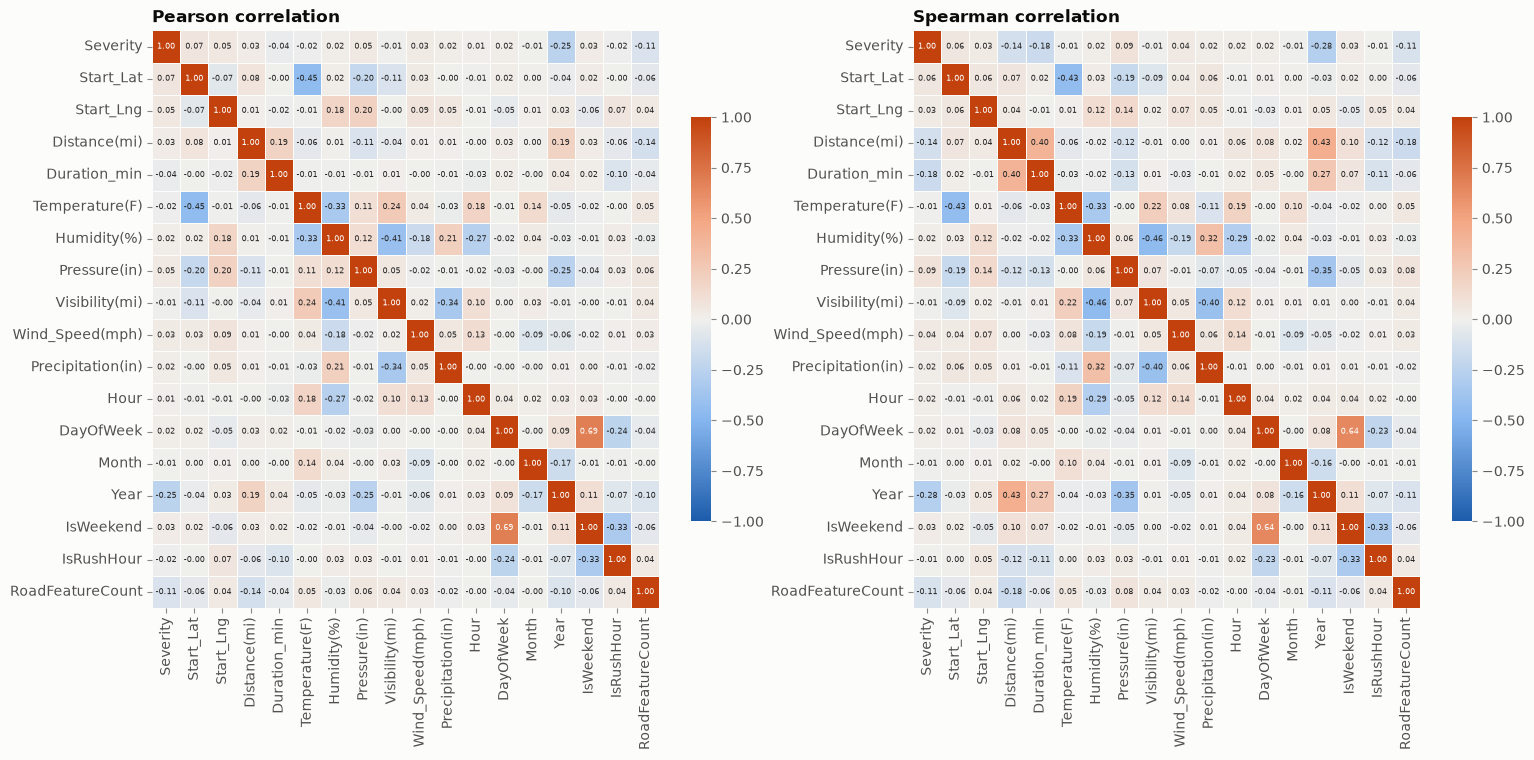

,pearson,spearman
Year,-0.2467,-0.2808
Duration_min,-0.0381,-0.1788
Distance(mi),0.0262,-0.1372
RoadFeatureCount,-0.1071,-0.1146
Pressure(in),0.0455,0.0870
Start_Lat,0.0688,0.0597
Wind_Speed(mph),0.0337,0.0416
Start_Lng,0.0531,0.0330
IsWeekend,0.0306,0.0271
Precipitation(in),0.0181,0.0228


In [13]:
ccols = ["Severity", "Start_Lat", "Start_Lng", "Distance(mi)", "Duration_min", "Temperature(F)", "Humidity(%)",
         "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "Hour", "DayOfWeek", "Month",
         "Year", "IsWeekend", "IsRushHour", "RoadFeatureCount"]
pear = df[ccols].corr("pearson"); spear = df[ccols].corr("spearman")
pear.round(4).to_csv(MET / "correlation_pearson.csv"); spear.round(4).to_csv(MET / "correlation_spearman.csv")
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for a, m, t in zip(axes, [pear, spear], ["Pearson", "Spearman"]):
    sns.heatmap(m, ax=a, cmap=V.DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 6},
                cbar_kws={"shrink": 0.7}, linewidths=0.5, linecolor=V.SURFACE)
    a.set_title(f"{t} correlation"); a.grid(False)
V.save(fig, FIG / "correlation_heatmaps.png")
sev_corr = pd.DataFrame({"pearson": pear["Severity"], "spearman": spear["Severity"]}).drop("Severity")
sev_corr = sev_corr.reindex(sev_corr["spearman"].abs().sort_values(ascending=False).index).round(4)
sev_corr.to_csv(MET / "severity_correlations.csv")
sev_corr

### 5.2 Cramer's V of categorical variables vs Severity

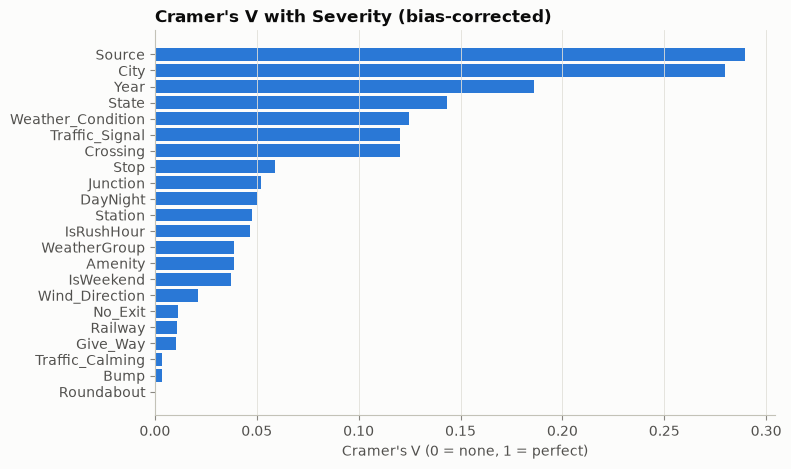

Strongest numeric link to Severity: Year (Spearman -0.28); strongest categorical: Source (V=0.29), then City (V=0.28).


,cramers_v
Source,0.2898
City,0.2797
Year,0.1861
State,0.1433
Weather_Condition,0.1248
Traffic_Signal,0.1201
Crossing,0.1201
Stop,0.0587
Junction,0.0521
DayNight,0.0503


In [14]:
cats = ["Source", "State", "City", "WeatherGroup", "Weather_Condition", "Wind_Direction", "DayNight", "Year",
        "IsWeekend", "IsRushHour"] + [c for c in U.ROAD_FEATURES if c in df]
cv = pd.Series({c: cramers_v(df[c], df["Severity"]) for c in cats}).sort_values(ascending=False).round(4)
cv.rename("cramers_v").to_csv(MET / "cramers_v.csv", header=True)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(cv.index[::-1], cv.values[::-1], color=V.PRIMARY); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title="Cramer's V with Severity (bias-corrected)", xlabel="Cramer's V (0 = none, 1 = perfect)")
V.save(fig, FIG / "cramers_v.png")
sc0 = sev_corr.index[0]
insights["correlation"] = (f"Strongest numeric link to Severity: {sc0} (Spearman {sev_corr.loc[sc0, 'spearman']:+.2f}); "
                           f"strongest categorical: {cv.index[0]} (V={cv.iloc[0]:.2f}), then {cv.index[1]} (V={cv.iloc[1]:.2f}).")
print(insights["correlation"])
cv.to_frame("cramers_v")

## 6. Time patterns

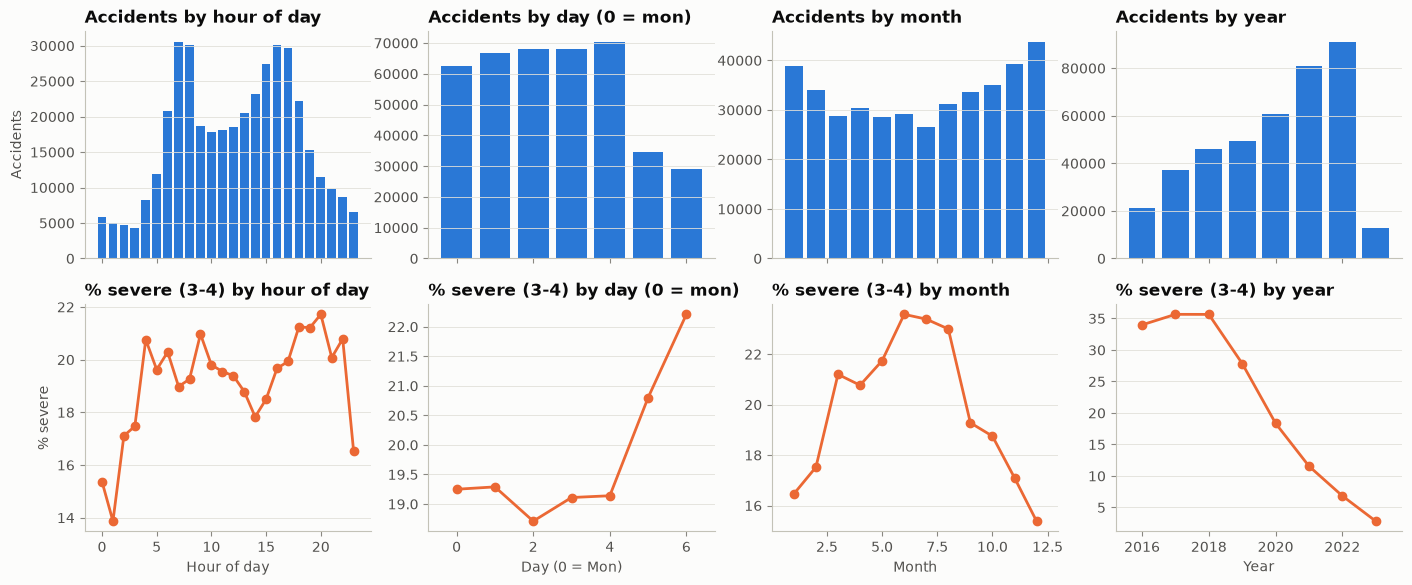

Peak hours are 07:00 and 16:00; a weekend day averages 53% fewer accidents than a weekday.
Severe share falls from 33.99% in 2016 to 2.83% in 2023 while counts rise - a change in data collection, so Year is not used as an ML feature.


In [15]:
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_hour = group_summary(df, "Hour", sort_by_count=False)
by_wd = group_summary(df, "DayOfWeek", sort_by_count=False); by_wd.insert(1, "DayName", [day_names[i] for i in by_wd["DayOfWeek"]])
by_month = group_summary(df, "Month", sort_by_count=False)
by_year = group_summary(df, "Year", sort_by_count=False)
for name, t in [("by_hour", by_hour), ("by_weekday", by_wd), ("by_month", by_month), ("by_year", by_year)]:
    t.to_csv(MET / f"{name}.csv", index=False)
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5), sharex="col")
for j, (t, x, lab) in enumerate([(by_hour, "Hour", "Hour of day"), (by_wd, "DayOfWeek", "Day (0 = Mon)"),
                                 (by_month, "Month", "Month"), (by_year, "Year", "Year")]):
    axes[0, j].bar(t[x], t["accidents"], color=V.PRIMARY); axes[0, j].set_title(f"Accidents by {lab.lower()}")
    axes[1, j].plot(t[x], t["severe_pct"], marker="o", color=V.ACCENT); axes[1, j].set_title(f"% severe (3-4) by {lab.lower()}")
    axes[1, j].set_xlabel(lab)
axes[0, 0].set_ylabel("Accidents"); axes[1, 0].set_ylabel("% severe")
V.save(fig, FIG / "time_patterns.png")
pk = by_hour.nlargest(2, "accidents")["Hour"].tolist()
wkday_mean = by_wd.loc[by_wd.DayOfWeek < 5, "accidents"].mean(); wkend_mean = by_wd.loc[by_wd.DayOfWeek >= 5, "accidents"].mean()
insights["time"] = (f"Peak hours are {pk[0]:02d}:00 and {pk[1]:02d}:00; a weekend day averages "
                    f"{100 * (1 - wkend_mean / wkday_mean):.0f}% fewer accidents than a weekday.")
y0, y1 = by_year.iloc[0], by_year.iloc[-1]
insights["year_artifact"] = (f"Severe share falls from {y0['severe_pct']}% in {int(y0['Year'])} to {y1['severe_pct']}% in {int(y1['Year'])} "
                             "while counts rise - a change in data collection, so Year is not used as an ML feature.")
print(insights["time"]); print(insights["year_artifact"])

### 6.1 Road infrastructure vs severity (query reused from the upstream analysis)

In [16]:
infra = infrastructure_summary(df, ["Traffic_Signal", "Junction", "Crossing", "Stop", "Railway", "Station"])
infra.to_csv(MET / "infrastructure.csv", index=False)
pv = infra.pivot(index="feature", columns="present", values="severe_pct")
insights["infrastructure"] = (f"Accidents near a junction are severe {pv.loc['Junction', True]}% of the time vs {pv.loc['Junction', False]}% elsewhere; "
                              f"near a traffic signal only {pv.loc['Traffic_Signal', True]}% vs {pv.loc['Traffic_Signal', False]}%.")
print(insights["infrastructure"])
infra

Accidents near a junction are severe 26.75% of the time vs 18.9% elsewhere; near a traffic signal only 9.54% vs 21.2%.


,feature,present,accidents,avg_severity,severe_pct
0,Traffic_Signal,False,340438,2.2337,21.20
1,Traffic_Signal,True,59143,2.0906,9.54
2,Junction,False,370228,2.2058,18.90
3,Junction,True,29353,2.2971,26.75
4,Crossing,False,354580,2.2312,21.05
5,Crossing,True,45001,2.0650,7.04
6,Stop,False,388544,2.2163,19.84
7,Stop,True,11037,2.0792,6.43
8,Railway,False,396182,2.2129,19.51
9,Railway,True,3399,2.1665,15.71


## 7. Duration (post-event, EDA only)

In [17]:
dur = df.groupby("Severity")["Duration_min"].median().round(1)
insights["duration"] = f"Median traffic-impact duration rises from {dur[1]} min (Severity 1) to {dur[4]} min (Severity 4)."
print(insights["duration"]); dur.to_frame("median_duration_min")

Median traffic-impact duration rises from 44.7 min (Severity 1) to 127.2 min (Severity 4).


,median_duration_min
Severity,
1,44.7
2,77.4
3,44.4
4,127.2


In [18]:
U.save_json(insights, MET / "eda_insights.json")
for k, v in insights.items():
    print(f"- {k}: {v}")

- severity: Severity 2 makes up 79.66% of accidents and Severity 1 only 0.87%; the largest class is 91x the smallest, so accuracy alone is misleading and macro-F1 is used in Module 4.
- weather: Rain has the highest severe share (22.87%) vs Fog/Haze the lowest (15.81%); overall 19.47%. The link is significant (chi-square p<1e-300) but weak (Cramer's V=0.039).
- weather_numeric: Strongest numeric weather effect: Pressure(in) (epsilon^2=0.0106); all six effects are below 0.06 (negligible/small), so single weather readings separate severity levels only slightly.
- states: CA, FL and TX record the most accidents (41.5% of all); top city is Miami, FL (186,768). Counts are not rates (no traffic volume).
- hotspots: Densest 0.1-degree cell: around Los Angeles, CA with 50,254 accidents; the top 10 cells hold 4.6% of all accidents.
- dbscan: DBSCAN (2 km, 25 points) finds 302 dense urban clusters; the largest is around Los Angeles, CA; 57.81% of accidents are outside any dense cluster.
- correl